# 0. Imports and defaults

In [5]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

In [ ]:
# Default parameters for testing

# input database folder
db_dir = 'input_databases//default'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h

# NEW: subsidy growth 
subsidy_growth_base = 0.0
subsidy_growth_high = 0.3 # To be verified 
subsidy_growth_low = -0.3 # To be verified 


# NEW: demand parameters (insulation parameters)
# saturation: max share of highly insulated houses
K_base  = 0.70    
K_high = 0.90 #  
K_low = 0.50 

s0 = 0.26    # share of highly insulated houses at t = 0 [VERIFIED]
r  = 0.032   # growth rate [NOT VERIFIED]
R  = 0.32    # demand reduction for highly insulated houses [VERIFIED]
T0 = 2020   # reference year, so t = model_year - 2000


In [3]:
# Handy plotting functions

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1,2)
    fig.set_size_inches(16,8)

    for n,c in enumerate([# 'Residential electricity',
            'Residential heat high',
            'Residential heat low',
            # 'Transportation',
            # 'Industrial machinery',
            # 'Industrial HTP'
            ]): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20',ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20', ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


# 1. Model Run

In [6]:
base = model_run(db_dir,years,t_res,passenger_cars_cf,rt,rs, subsidy_growth_base, K_base, s0, r, R, T0)
base.name = 'base'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 324.32it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-c3up5ozo.lp
Reading time = 0.41 seconds
obj: 289174 rows, 133823 columns, 663350 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.72397669487754e+20


In [7]:
# High insulation, high subsidy scenario 
tandem = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_high, K_high, s0, r, R, T0)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 324.85it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-pu6cr0f0.lp
Reading time = 0.41 seconds
obj: 289174 rows, 133823 columns, 663350 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694770682e+20


In [8]:
# High insulation, low subsidy scenario 
insulation_first = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_low, K_high, s0, r, R, T0)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 339.65it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-s18ormxo.lp
Reading time = 0.48 seconds
obj: 289174 rows, 133823 columns, 663350 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694780832e+20


In [9]:
# Low insulation, high subsidy scenario 
technology_first = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_high, K_low, s0, r, R, T0)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 191.04it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-ph9slq9_.lp
Reading time = 0.65 seconds
obj: 289174 rows, 133823 columns, 663350 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694936223e+20


In [10]:
# Low insulation, low subsidy scenario 
alternative_route = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_low, K_low, s0, r, R, T0)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 443.22it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-ei_ihj25.lp


Reading time = 0.43 seconds
obj: 289174 rows, 133823 columns, 663350 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694944013e+20


# 2. Plots
## Energy balance 

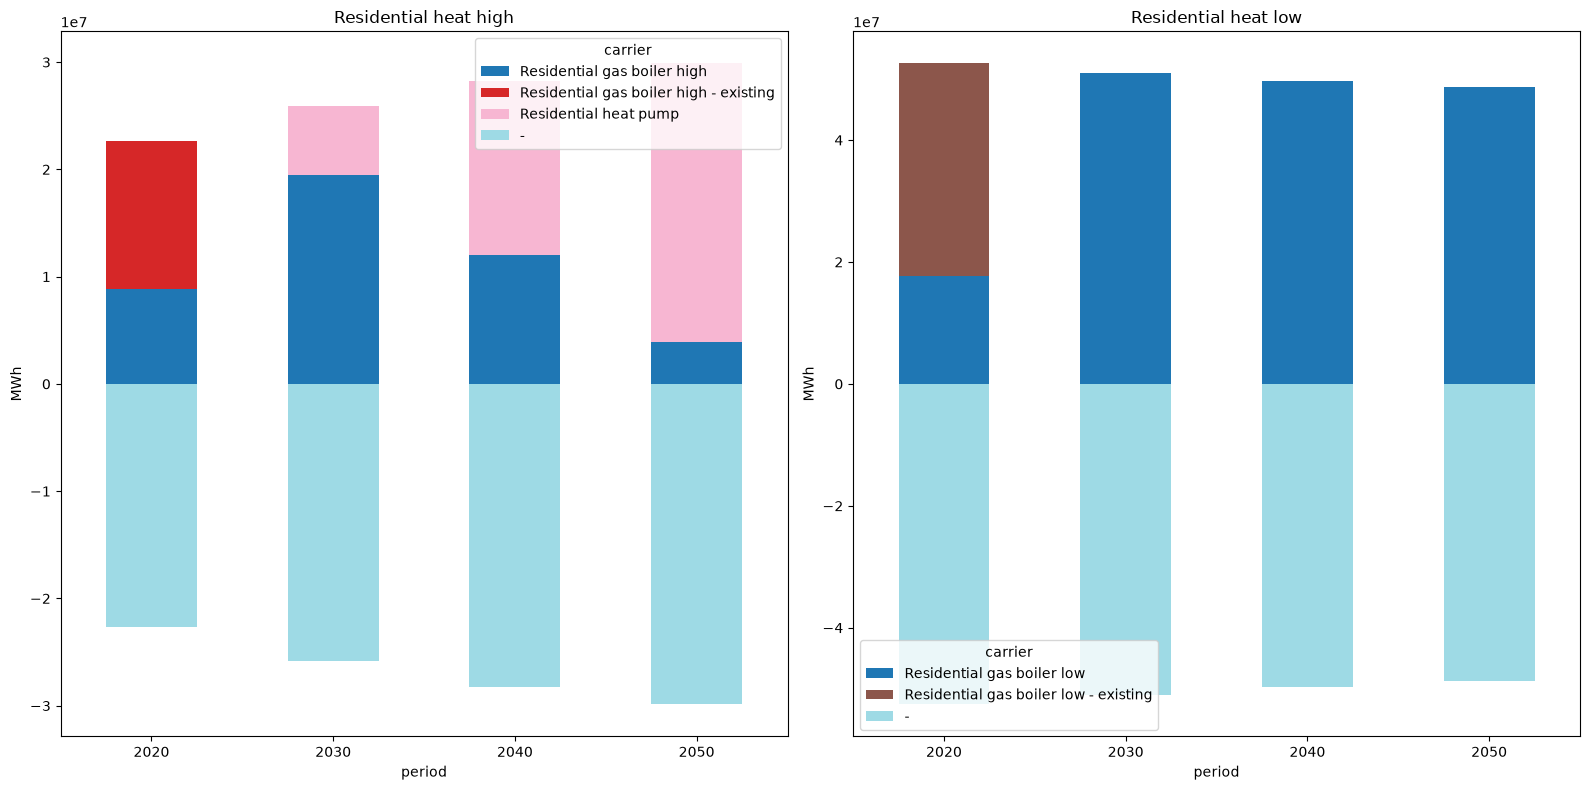

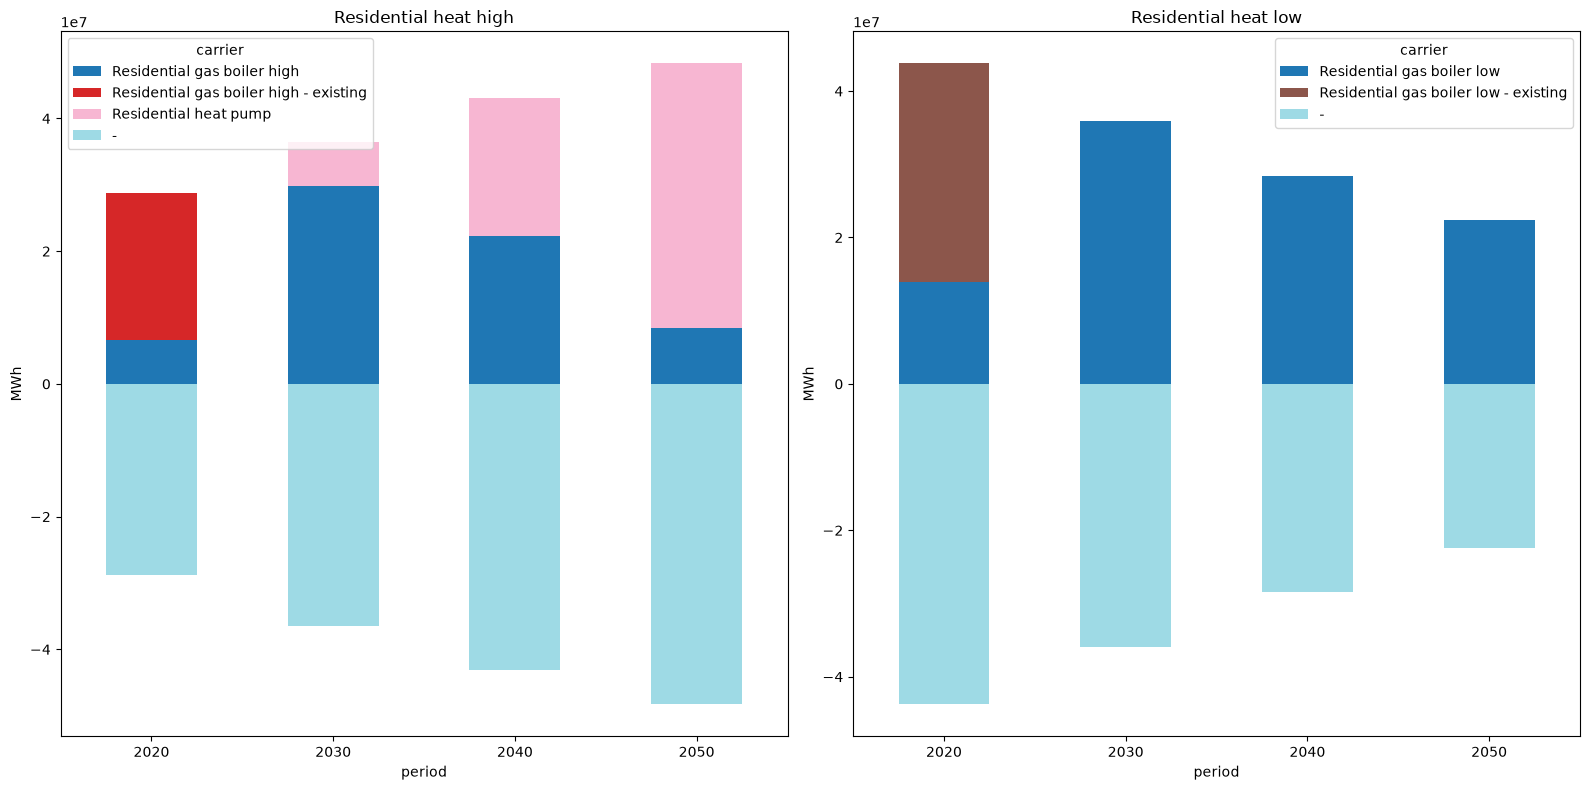

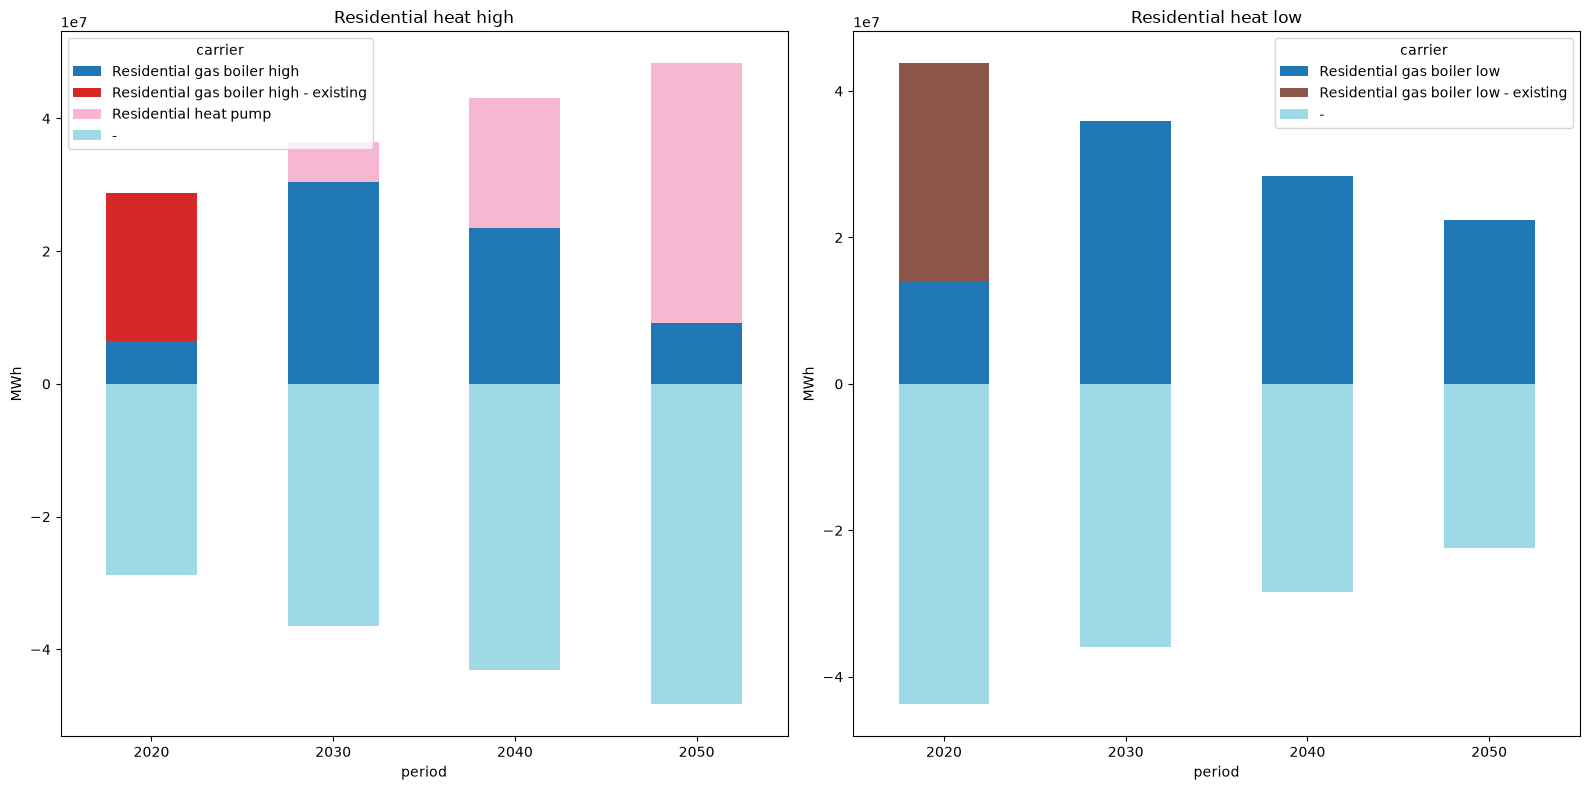

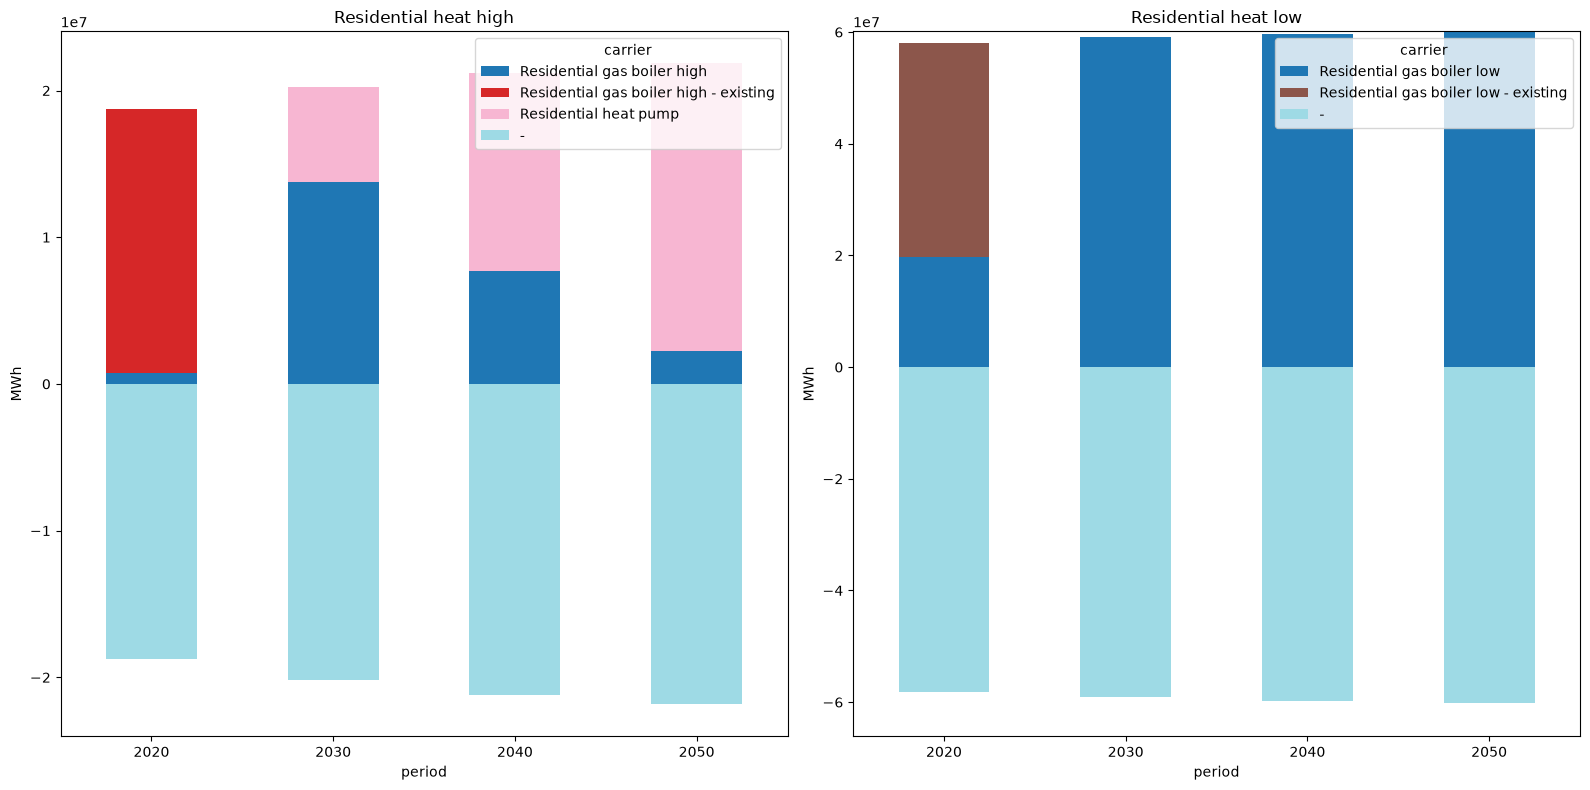

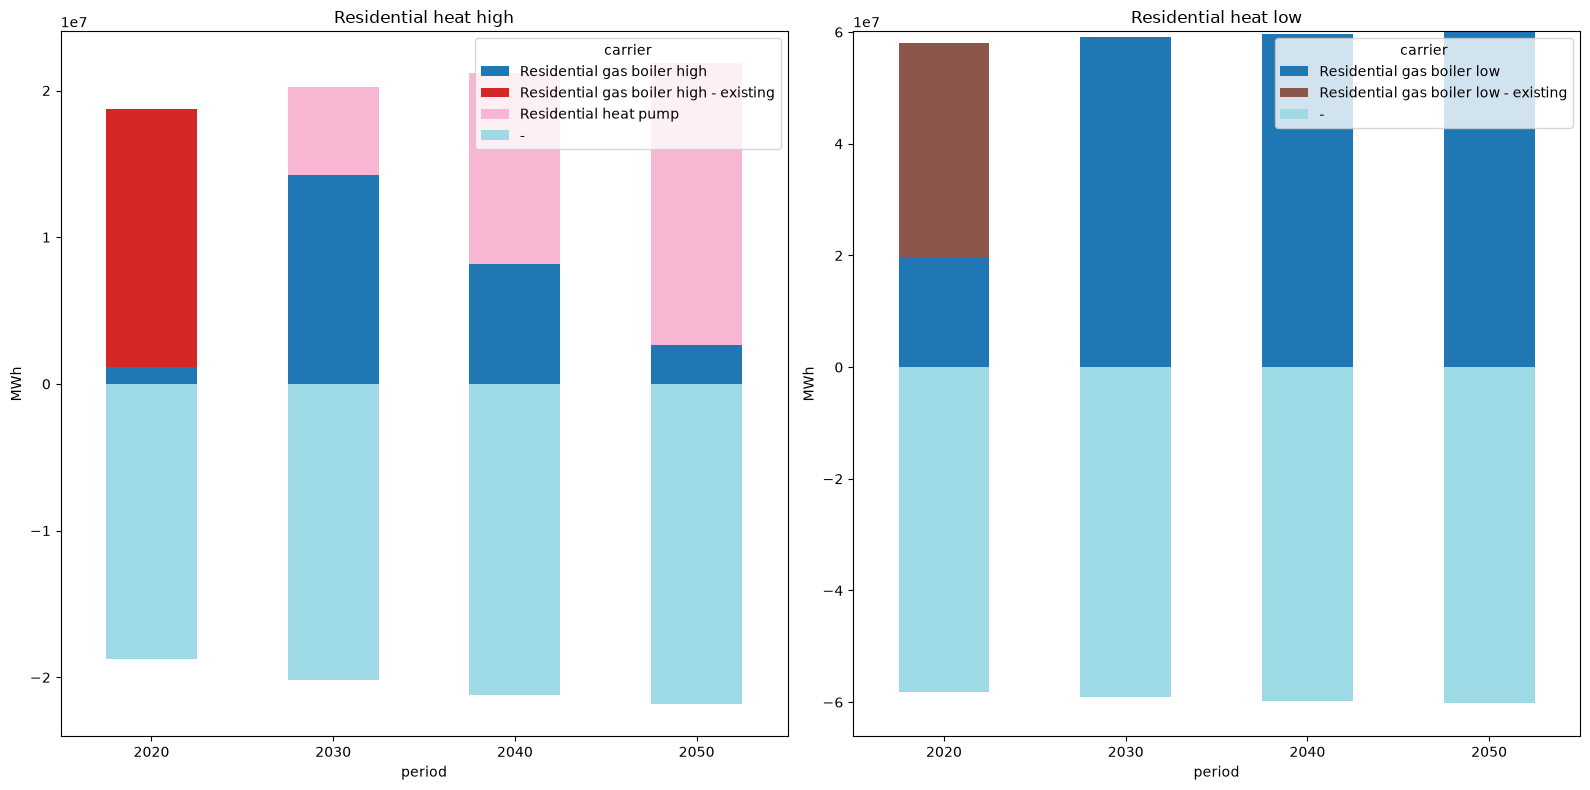

In [16]:
# Let's have a quick look at the demand-side energy balances:
plot_main_ebs(base)
plot_main_ebs(tandem)
plot_main_ebs(insulation_first)
plot_main_ebs(technology_first)
plot_main_ebs(alternative_route)

## Electricity supply and emissions

/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/ipykernel_82383/3370736470.py:49: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


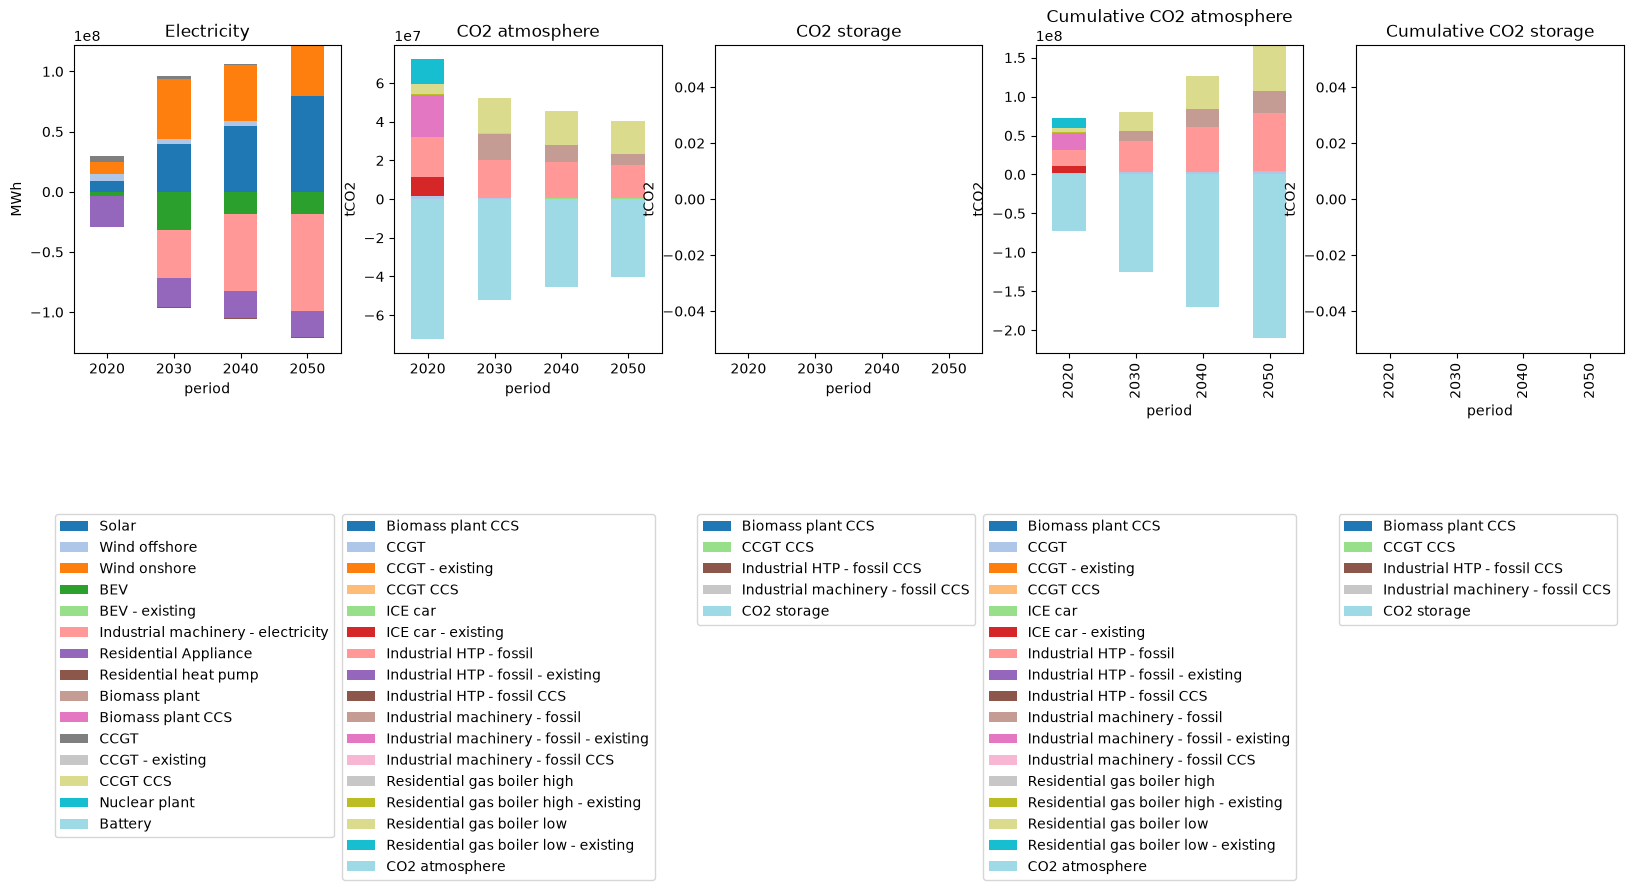

In [ ]:
# Let's also look at electricity supply and emissions
plot_elc_emi(base)

As solar PV and wind energy become cheaper, from 2040 electricity naturally starts taking over large portions of passenger transportation, residential heat and industrial machinery. Industrial HTP remains fully fossil-fuel-based. Emissions naturally decrease, and in 2050 they are mostly due to industrial activity. The CO2 budget of 1 GtCO2 is not fully utilized.  

There are a couple of things happening in the model: 
- As wind and solar become cheaper, so does the average electricity price;
- Gas reserves ($10^9$ MWh) are fully depleted;
- As gas resources deplete its (shadow) price increases;
- Gasoline and CO2 reserves (resp $10^9$ MWh and 1 GtCO2) are by far not fully utilized, hence their (shadow) price remains 0.

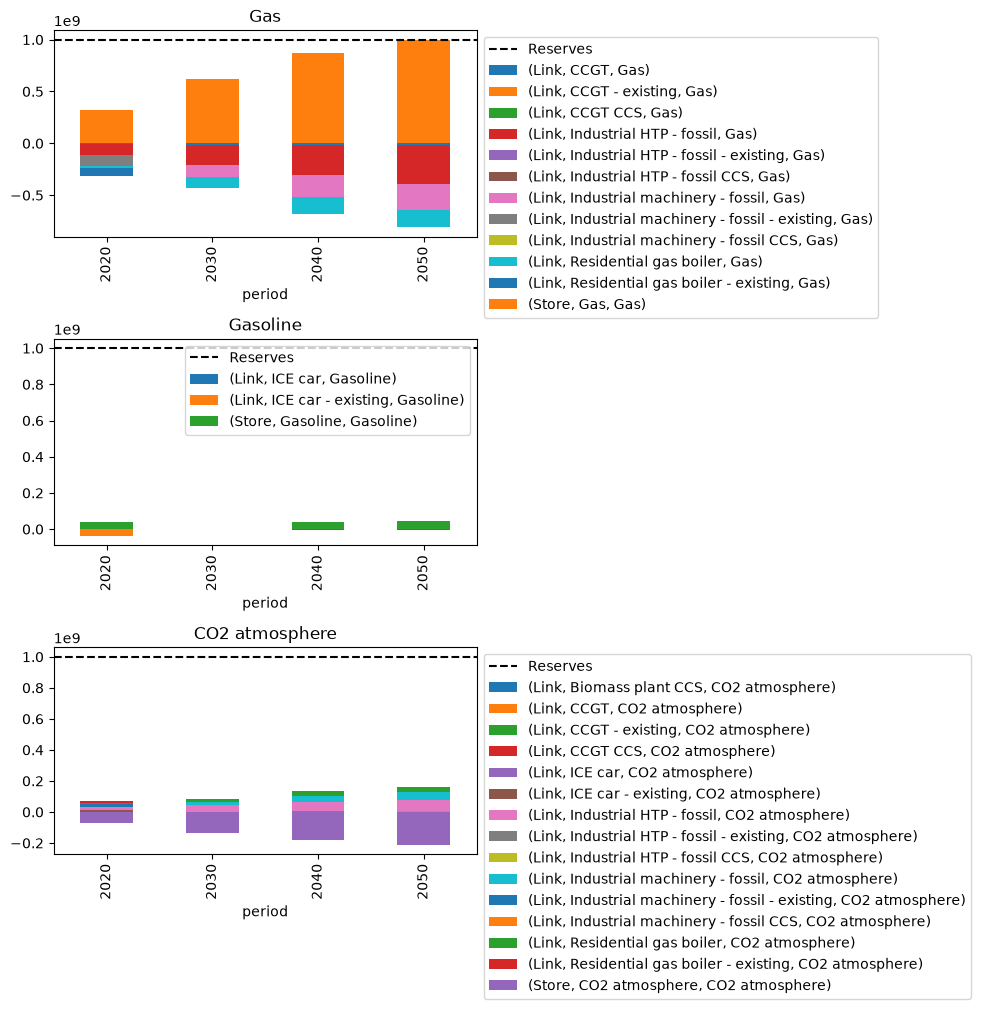

In [ ]:
# Let's show that gas reserves are fully depleted by 2050, while gasoline reserves are not:
fig, ax = plt.subplots(3,1)
fig.set_size_inches(10,10)
reserves = {'Gas':1e9, 'Gasoline':1e9, 'CO2 atmosphere':1e9}
for n,c in enumerate(['Gas', 'Gasoline','CO2 atmosphere']):
    base.statistics.energy_balance(bus_carrier=c).cumsum(axis=1).T.plot(kind='bar', stacked=True, ax=ax[n])
    ax[n].hlines(reserves[c],-0.5,4.5, label='Reserves', ls='--', color='black')
    ax[n].legend(bbox_to_anchor=(1,1))
    ax[n].set_title(c)
plt.tight_layout()

In [ ]:
# Show shadow prices of electricity, gas, gasoline and CO2 atmosphere
base.buses_t.marginal_price.groupby(level=0).agg('mean')[['Electricity','Gas supply','Gasoline supply','CO2 atmosphere']]

name,Electricity,Gas supply,Gasoline supply,CO2 atmosphere
period,,,,
2020,369.696422,31.912762,0.0,0.0
2030,222.582745,35.251543,0.0,0.0
2040,160.125626,38.939634,0.0,0.0
2050,132.906150,43.013581,0.0,0.0


## Heat map 